# Assignment 3 · Parte 2: Mapas del Perú

In [1]:
from pathlib import Path
import unicodedata

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import mapclassify
import numpy as np
from matplotlib.patches import Patch
import folium
from folium.features import GeoJsonTooltip

## 1. Carga de datos

In [2]:
datos = Path("datos")
df = pd.read_csv(datos / "tabla-final.csv", dtype={"ubigeo": str})
peru = gpd.read_file(datos / "departamentos_peru.geojson")

df["ubigeo"] = df["ubigeo"].str.strip().str.zfill(2)
print("CSV:", df.shape, "| Geometrías:", peru.shape, "| CRS:", peru.crs)
display(df.head())
print("Nulos en indicadores:")
print(df[["departamento", "ubigeo", "lluvia_total_mm", "dias_lluvia_fuerte", "declaratorias"]].isna().sum())
print("Ubigeos duplicados:", df["ubigeo"].duplicated().sum())

CSV: (25, 9) | Geometrías: (25, 2) | CRS: EPSG:4326


,ubigeo,departamento,capital,latitud,longitud,lluvia_total_mm,dias_lluvia_fuerte,declaratorias,prorrogas
0,01,Amazonas,Chachapoyas,-6.23169,-77.86903,436.5,1,1,0
1,02,Áncash,Huaraz,-9.52614,-77.52869,975.3,7,0,0
2,03,Apurímac,Abancay,-13.63426,-72.88380,711.8,2,0,0
3,04,Arequipa,Arequipa,-16.39899,-71.53747,189.9,0,0,0
4,05,Ayacucho,Ayacucho,-13.16380,-74.22345,485.1,0,1,0


Nulos en indicadores:
departamento          0
ubigeo                0
lluvia_total_mm       0
dias_lluvia_fuerte    0
declaratorias         0
dtype: int64
Ubigeos duplicados: 0


## 2. Correlacion entre nombres y ubigeo

In [3]:
def normalizar(texto):
    texto = unicodedata.normalize("NFKD", str(texto).strip().upper())
    return "".join(c for c in texto if not unicodedata.combining(c))

estadistica = df.copy()
geo = peru.copy()
estadistica["clave_nombre"] = estadistica["departamento"].map(normalizar)
geo["clave_nombre"] = geo["departamento"].map(normalizar)

correspondencia = estadistica[["clave_nombre", "ubigeo"]].drop_duplicates()
assert correspondencia["clave_nombre"].is_unique, "Nombres repetidos en la correspondencia"
assert correspondencia["ubigeo"].is_unique, "Ubigeos repetidos en el CSV"

geo = geo.merge(correspondencia, on="clave_nombre", how="left", validate="one_to_one")
print("Geometrías sin ubigeo asignado:")
display(geo.loc[geo["ubigeo"].isna(), ["departamento", "clave_nombre"]])

mapa_final = geo.merge(
    estadistica.drop(columns="clave_nombre"),
    on="ubigeo", how="left", validate="one_to_one",
    indicator=True, suffixes=("_mapa", "_datos")
)
print("Estado del cruce por ubigeo:")
print(mapa_final["_merge"].value_counts().to_string())
print("Geometrías sin dato estadístico:")
display(mapa_final.loc[mapa_final["_merge"] != "both", ["ubigeo", "departamento_mapa"]])
print("Datos estadísticos sin geometría:")
display(estadistica.loc[~estadistica["ubigeo"].isin(geo["ubigeo"]), ["ubigeo", "departamento"]])

assert len(mapa_final) == len(geo) == len(estadistica) == 25
assert mapa_final["_merge"].eq("both").all(), "Existen departamentos sin cruce"
assert mapa_final.geometry.notna().all()
assert mapa_final[["lluvia_total_mm", "dias_lluvia_fuerte"]].notna().all().all()
print("Validación del cruce completada: 25 coincidencias.")

Geometrías sin ubigeo asignado:


,departamento,clave_nombre


Estado del cruce por ubigeo:
_merge
both          25
left_only      0
right_only     0
Geometrías sin dato estadístico:


,ubigeo,departamento_mapa


Datos estadísticos sin geometría:


,ubigeo,departamento


Validación del cruce completada: 25 coincidencias.


## 3. Analisis de precipitaciones acumuladas

Text(0.5, 1.0, 'Distribución territorial de las precipitaciones acumuladas en el Perú')

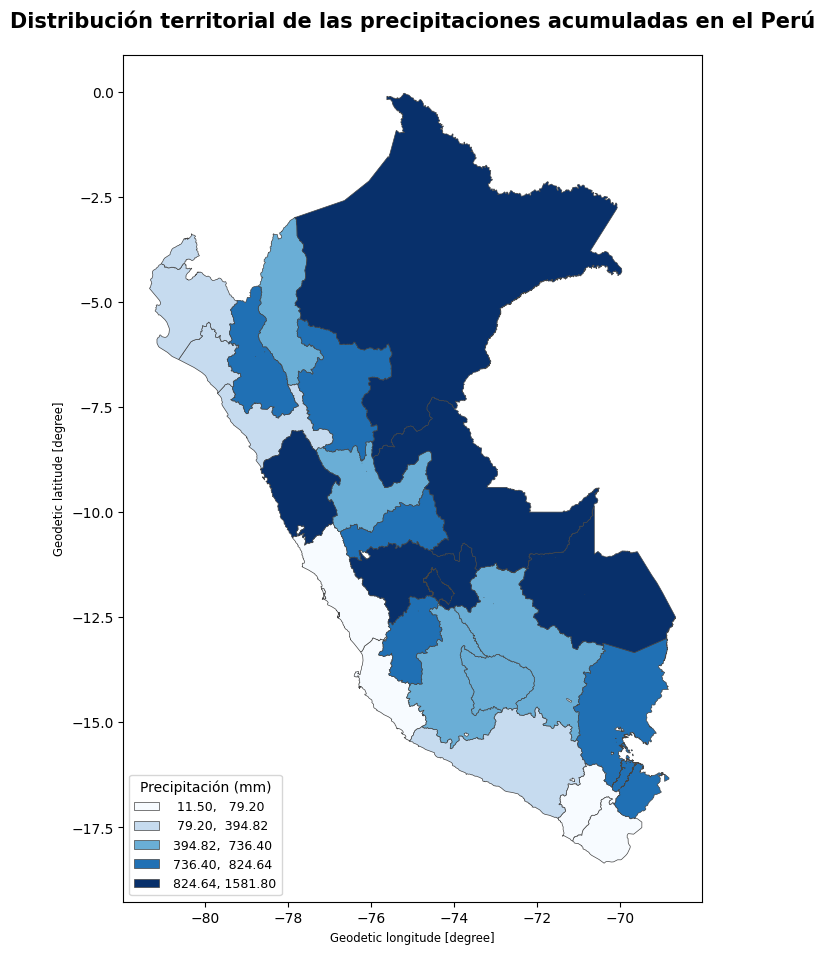

In [7]:
fig, ax = plt.subplots(figsize=(10, 11))
mapa_final.plot(
    column="lluvia_total_mm", scheme="Quantiles", k=5,
    cmap="Blues", legend=True, edgecolor="#444444", linewidth=0.5,
    legend_kwds={"loc": "lower left", "title": "Precipitación (mm)", "fontsize": 9}, ax=ax
)
ax.set_title(
    "Distribución territorial de las precipitaciones acumuladas en el Perú",
    fontsize=15,
    fontweight="bold",
    pad=20
)

El mapa permite observar diferencias en los niveles de precipitación acumulada registrados entre las capitales departamentales del Perú. Entre los resultados obtenidos destacan Loreto, con 1581.8 mm, y Ucayali, con 1288.8 mm, que presentan los valores más elevados. Por otro lado, también se identifican departamentos con registros considerablemente menores, lo que permite apreciar las diferencias existentes entre las capitales analizadas.

## 4. Analisis de días de lluvia fuerte

Text(0.5, 1.0, 'Distribución territorial de los días de lluvia fuerte en el Perú')

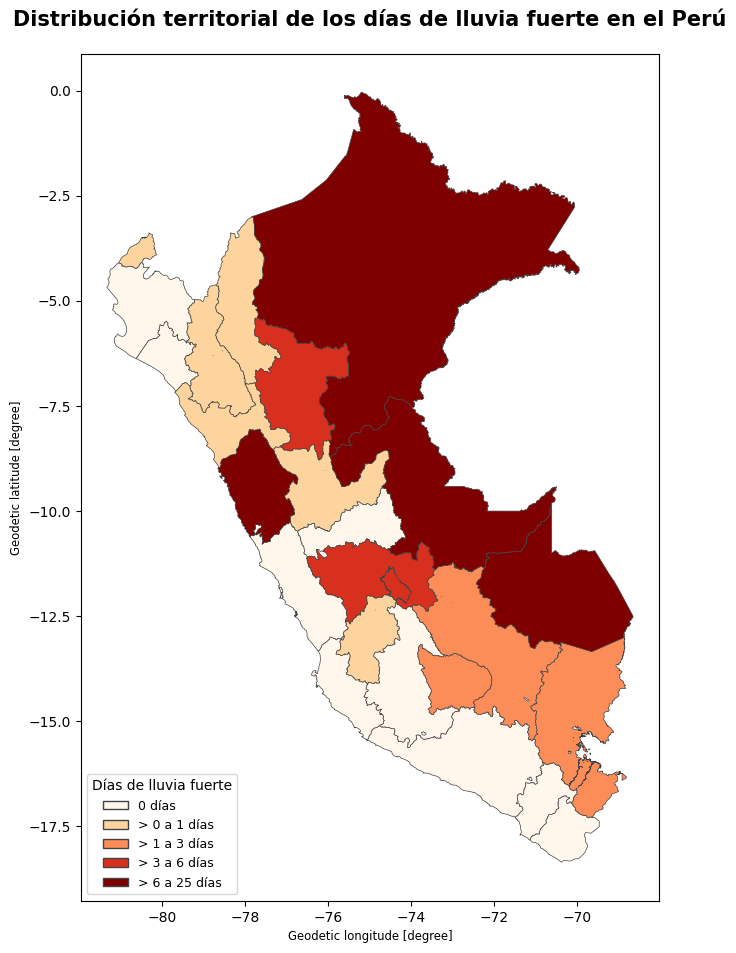

In [8]:
mapa_dias = mapa_final.copy()
positivos = mapa_dias.loc[mapa_dias["dias_lluvia_fuerte"] > 0, "dias_lluvia_fuerte"]
assert not positivos.empty, "No hay valores positivos para clasificar"

clasificador = mapclassify.Quantiles(positivos, k=min(4, positivos.nunique()))
cortes = np.unique(clasificador.bins)
mapa_dias["clase"] = 0
mapa_dias.loc[positivos.index, "clase"] = np.searchsorted(cortes, positivos, side="left") + 1
mapa_dias["clase"] = mapa_dias["clase"].astype(int)

colores = plt.get_cmap("OrRd", len(cortes) + 1)
fig, ax = plt.subplots(figsize=(10, 11))
mapa_dias.plot(column="clase", categorical=True, cmap=colores, legend=False,
               edgecolor="#444444", linewidth=0.5, ax=ax)

etiquetas = ["0 días"]
inferior = 0
for superior in cortes:
    etiquetas.append(f"> {inferior:g} a {superior:g} días")
    inferior = superior
muestras = [Patch(facecolor=colores(i), edgecolor="#444444", label=etiqueta)
            for i, etiqueta in enumerate(etiquetas)]
ax.legend(handles=muestras, title="Días de lluvia fuerte", loc="lower left", fontsize=9)
ax.set_title(
    "Distribución territorial de los días de lluvia fuerte en el Perú",
    fontsize=15,
    fontweight="bold",
    pad=20
)

En relación con la cantidad de días de lluvia fuerte, se observan diferencias entre las capitales departamentales. Loreto presenta el mayor registro, con 25 días, seguido de Ucayali, con 20 días. Asimismo, se identifican departamentos que no registraron días de lluvia fuerte durante el periodo analizado, lo que permite observar que la frecuencia de estos eventos no fue uniforme entre las capitales consideradas.

## 5. Mapa interactivo de precipitaciones 

In [6]:
mapa_folium = mapa_final.drop(columns="_merge").copy()
mapa_folium["departamento_mapa"] = mapa_folium["departamento_mapa"].astype(str)

m = folium.Map(location=[-9.2, -75.0], zoom_start=5,
               tiles="OpenStreetMap", control_scale=True, height=600)
folium.Choropleth(
    geo_data=mapa_folium.to_json(), data=mapa_folium,
    columns=["ubigeo", "lluvia_total_mm"],
    key_on="feature.properties.ubigeo", fill_color="YlGnBu",
    fill_opacity=0.75, line_opacity=0.35,
    legend_name="Precipitación acumulada (mm)", name="Precipitaciones"
).add_to(m)
folium.GeoJson(
    mapa_folium.to_json(), name="Información departamental",
    style_function=lambda f: {"fillOpacity": 0, "color": "#333333", "weight": 0.5},
    highlight_function=lambda f: {"color": "#111111", "weight": 2},
    tooltip=GeoJsonTooltip(
        fields=["departamento_mapa", "lluvia_total_mm", "dias_lluvia_fuerte", "declaratorias"],
        aliases=["Departamento:", "Precipitación (mm):", "Días de lluvia fuerte:", "Declaratorias:"],
        localize=True, sticky=False
    )
).add_to(m)
limites = mapa_folium.total_bounds
m.fit_bounds([[limites[1], limites[0]], [limites[3], limites[2]]])
folium.LayerControl().add_to(m)

# Exportación opcional fuera del notebook, sin almacenar una salida pesada.
Path("resultados").mkdir(exist_ok=True)
m.save("resultados/mapa_interactivo_peru.html")
m

El mapa interactivo permite consultar la información correspondiente a cada departamento y facilita la identificación de sus valores de precipitación acumulada y días de lluvia fuerte. Es asi pues que si se realizase una comparativa entre Los mapas y los graficos se puede observar como los mapas permiten identificar la ubicación geográfica de los departamentos y observar cómo se distribuyen territorialmente los valores registrados. En cambio, los gráficos de barras facilitan la comparación de las magnitudes y permiten identificar con mayor precisión las diferencias entre departamentos. 